# 🧼 Ejemplo en clase: ventas de cafeterías
**Dataset:** `ventas_cafeteria.csv` · 200 filas · 9 columnas (ventas de septiembre 2026 de 4 sucursales).

**Objetivo:** hacer el "diagnóstico clínico" del dataset y decidir, columna por columna, qué limpiar y qué conservar.

> En Google Colab: subí el CSV desde el panel de archivos (📁) antes de ejecutar.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('ventas_cafeteria.csv')
df.head()

,id_transaccion,fecha_hora,sucursal,producto,cantidad,precio_unitario,medio_pago,edad_cliente,descuento_aplicado
0,T-0001,2026-09-01 09:16:00,Norte,Capuccino,1,3000.0,Tarjeta,32.0,NaN
1,T-0002,2026-09-01 09:39:00,Centro,Café latte,3,2800.0,Tarjeta,18.0,NaN
2,T-0003,2026-09-01 13:45:00,Centro,Capuccino,2,3000.0,Efectivo,29.0,20.0
3,T-0004,2026-09-01 15:08:00,Norte,Café latte,3,2800.0,Efectivo,42.0,NaN
4,T-0005,2026-09-01 16:44:00,Este,Té,1,1800.0,Billetera virtual,40.0,NaN


## 1. Explorar
`info()` muestra cuántos valores *Non-Null* hay por columna.

In [2]:
print(df.shape)
df.info()

(200, 9)
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_transaccion      200 non-null    str    
 1   fecha_hora          200 non-null    str    
 2   sucursal            200 non-null    str    
 3   producto            200 non-null    str    
 4   cantidad            200 non-null    int64  
 5   precio_unitario     196 non-null    float64
 6   medio_pago          196 non-null    str    
 7   edad_cliente        175 non-null    float64
 8   descuento_aplicado  83 non-null     float64
dtypes: float64(3), int64(1), str(5)
memory usage: 14.2 KB


## 2. Medir: ¿qué tan grave es?
Siempre en **porcentaje** (nulos ÷ total de filas).

In [3]:
resumen = pd.DataFrame({
    'nulos': df.isna().sum(),
    'porcentaje': (df.isna().sum() / len(df) * 100).round(1)
}).sort_values('porcentaje', ascending=False)
resumen

,nulos,porcentaje
descuento_aplicado,117,58.5
edad_cliente,25,12.5
precio_unitario,4,2.0
medio_pago,4,2.0
id_transaccion,0,0.0
cantidad,0,0.0
producto,0,0.0
sucursal,0,0.0
fecha_hora,0,0.0


## 3. Vacíos disfrazados
Una cadena vacía o un espacio `" "` **no es NaN** para Pandas. Miremos `medio_pago`:

In [4]:
df['medio_pago'].value_counts(dropna=False)

medio_pago
Efectivo             82
Tarjeta              63
Billetera virtual    48
NaN                   4
                      3
Name: count, dtype: int64

In [5]:
# Convertimos textos vacíos / solo espacios en NaN
df = df.replace(r'^\s*$', np.nan, regex=True)
df.isna().sum()

id_transaccion          0
fecha_hora              0
sucursal                0
producto                0
cantidad                0
precio_unitario         4
medio_pago              7
edad_cliente           25
descuento_aplicado    117
dtype: int64

## 4. Contextualizar (¡antes de limpiar!)
| Columna | Pregunta clave |
|---|---|
| `descuento_aplicado` (~58 % nulos) | ¿Es un error… o significa *"sin descuento"*? |
| `edad_cliente` (12,5 %) | ¿Puedo estimarla sin distorsionar? ¿media o mediana? |
| `medio_pago` (3,5 %) | Variable categórica con pocos faltantes |
| `precio_unitario` (2 %) | Es dato clave y faltan muy pocos |

👉 **Discutir en clase** y recién después seguir.

## 5. Duplicados

In [6]:
# Filas idénticas en TODAS las columnas
print('Duplicados exactos:', df.duplicated().sum())
df[df.duplicated(keep=False)]

Duplicados exactos: 6


,id_transaccion,fecha_hora,sucursal,producto,cantidad,precio_unitario,medio_pago,edad_cliente,descuento_aplicado
16,T-0017,2026-09-03 15:07:00,Este,Licuado,1,3200.0,Efectivo,28.0,NaN
17,T-0017,2026-09-03 15:07:00,Este,Licuado,1,3200.0,Efectivo,28.0,NaN
122,T-0120,2026-09-19 11:41:00,Sur,Capuccino,1,3000.0,Efectivo,18.0,20.0
123,T-0120,2026-09-19 11:41:00,Sur,Capuccino,1,3000.0,Efectivo,18.0,20.0
125,T-0122,2026-09-19 15:37:00,Norte,Capuccino,1,3000.0,Billetera virtual,41.0,20.0
126,T-0122,2026-09-19 15:37:00,Norte,Capuccino,1,3000.0,Billetera virtual,41.0,20.0
152,T-0148,2026-09-25 08:56:00,Centro,Capuccino,3,3000.0,Tarjeta,45.0,15.0
153,T-0148,2026-09-25 08:56:00,Centro,Capuccino,3,3000.0,Tarjeta,45.0,15.0
174,T-0169,2026-09-27 19:22:00,Norte,Té,2,1800.0,Billetera virtual,34.0,15.0
175,T-0169,2026-09-27 19:22:00,Norte,Té,2,1800.0,Billetera virtual,34.0,15.0


In [7]:
# Por la clave de negocio (ID de transacción)
print('Duplicados por id_transaccion:', df.duplicated(subset='id_transaccion').sum())

Duplicados por id_transaccion: 6


**¿Todo lo parecido es duplicado?** Mirá `T-0043` y `T-0194`: mismo producto, sucursal, pago y edad, pero **otro ID y otro día**. Es un *evento real* (el cliente volvió) → **se conserva**.

In [8]:
df[df['id_transaccion'].isin(['T-0043','T-0194'])]

,id_transaccion,fecha_hora,sucursal,producto,cantidad,precio_unitario,medio_pago,edad_cliente,descuento_aplicado
43,T-0043,2026-09-08 13:07:00,Centro,Tostado,3,3500.0,Efectivo,41.0,NaN
50,T-0194,2026-09-09 13:07:00,Centro,Tostado,3,3500.0,Efectivo,41.0,NaN


In [9]:
# Cuidado: elegir mal la clave marca como 'duplicado' casi todo
print(df.duplicated(subset=['sucursal','producto']).sum(), '← ¡no es una clave única!')

172 ← ¡no es una clave única!


## 6. Decidir y aplicar

In [10]:
filas_inicio = len(df)

# 1) Duplicados exactos = error del sistema -> BORRAR
df = df.drop_duplicates(subset='id_transaccion', keep='first')

# 2) precio_unitario: falta <5% y es dato clave -> eliminar esas filas
df = df.dropna(subset=['precio_unitario']).copy()

# 3) descuento_aplicado: NaN significa 'sin descuento' -> 0 (no es error)
df['descuento_aplicado'] = df['descuento_aplicado'].fillna(0)

# 4) medio_pago: categórica -> constante 'Desconocido' (conservamos la fila)
df['medio_pago'] = df['medio_pago'].fillna('Desconocido')

print(f'Filas: {filas_inicio} -> {len(df)}')

Filas: 200 -> 190


### Edad: ¿media o mediana?

Media  : 34.83
Mediana: 34.0


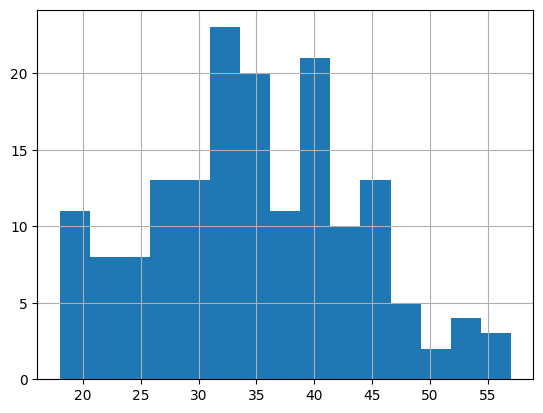

In [11]:
print('Media  :', round(df['edad_cliente'].mean(), 2))
print('Mediana:', df['edad_cliente'].median())
df['edad_cliente'].hist(bins=15);

In [12]:
# Sin outliers fuertes ambas sirven; usamos la mediana (más robusta)
mediana_edad = df['edad_cliente'].median()
df['edad_cliente'] = df['edad_cliente'].fillna(mediana_edad)
print('Media después de imputar:', round(df['edad_cliente'].mean(), 2))

Media después de imputar: 34.72


## 7. Verificar

In [13]:
print(df.shape)
print(df.isna().sum().sum(), 'nulos restantes')
df['descuento_aplicado'].value_counts()

(190, 9)
0 nulos restantes


descuento_aplicado
0.0     111
20.0     33
15.0     24
10.0     22
Name: count, dtype: int64

## 8. Documentar las decisiones
| Columna / problema | % | Decisión | Por qué |
|---|---|---|---|
| Duplicados exactos | 6 filas | Eliminar | Mismo ID y mismo timestamp: error del sistema |
| `precio_unitario` | 2 % | Eliminar filas | Dato clave, <5 %, no se inventa |
| `descuento_aplicado` | 58,5 % | Rellenar con 0 | Nulo = "sin descuento" (información de negocio) |
| `medio_pago` (+3 espacios) | 3,5 % | `'Desconocido'` | Categórica, conservamos la fila |
| `edad_cliente` | 12,5 % | Mediana | Variable importante; mediana robusta |
| Repetidos con otro ID/fecha | 3 | **Conservar** | Son compras distintas |

In [14]:
df.to_csv('ventas_cafeteria_limpio.csv', index=False)